# 04 - XGBoost models: with and without sentiment and delay

**Inputs:** `model_table.csv`, `feature_sets.json`, `cv_config.json`, `study_config.json` (notebooks 02-03).
**Helper code:** `src/forecast_utils.py` and `src/modelling.py`.
**Outputs:** predictions, tuning log, comparison tables and figures (`outputs/`).

## The question of the whole project
> *Does adding customer review sentiment (and delivery delay) to the past sales improve the forecast of next week's demand?*

This notebook answers it for the **main horizon, h = 1 week ahead**. Horizons 2 and 4, explanations (SHAP) and robustness come in notebook 05.

## The four models (same algorithm, different information)
| Model | Features | What it tells us |
|---|---|---|
| **XGB-A** | past orders + Black Friday flag | the reference: what sales history alone can do |
| **XGB-B** | A + sentiment (score, share of 1-2 stars) | does sentiment add anything? (**main test**) |
| **XGB-C** | A + delivery delay | does the delay add anything? |
| **XGB-D** | A + sentiment + delay | everything together |

Comparing B with A answers the research question. Comparing B with C and D shows whether sentiment adds anything *beyond* the delay (we saw that low scores mostly come from late deliveries).

## What is XGBoost, in simple words?
XGBoost builds **many small decision trees one after the other**; each new tree tries to fix the mistakes of the previous ones. You used it for classification before; here the same idea predicts a **number** (a regressor).

## Design choices (and why)
| Choice | Why |
|---|---|
| **One model for all 12 categories** (pooled) | One category gives only about 40 training rows, too few. Pooled we have about 500. The model can still be scored category by category. |
| **We predict a ratio** (`next week's orders / average of the last 4 weeks`) and multiply back | Demand **grows over time**, and a tree cannot predict values larger than anything it has seen. The ratio is stable (around 1), which trees handle well. Section 2 compares it with predicting raw orders. |
| **Black Friday flag** | One known event; without the flag the spike would confuse the model. It is known in advance, so it is not leakage. |
| **Tuning inside the training period only** | The settings (depth, learning rate, ...) are chosen by a small rolling validation on the *training* data of each fold. The test window is never touched. |
| **Same tuning budget for A, B, C, D** | Fairness: nobody gets better settings by luck. |
| **3 random seeds averaged** | XGBoost has some randomness; averaging stops us from mistaking noise for a real difference. |
| **Mean and spread over 9 rolling windows** | Advice of Denes (data supervisor). One split can be lucky or unlucky. |
| **Black Friday week reported separately** | Fold 1 contains it and no model could know it. Main results exclude it, and we show both. |

## 1. Setup and loading

In [14]:
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.append("../src")
import forecast_utils as fu
import modelling as mdl

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

PROCESSED = Path("../data/processed")
FIGURES = Path("../outputs/figures")
TABLES = Path("../outputs/tables")

# ----- Parameters -----
H = 1                      # main horizon (1 week ahead)
N_CONFIGS = 12             # how many random XGBoost settings are tried per fold and model
SEEDS = (0, 1, 2)          # final models are averaged over these seeds
TARGET_MODE = "ratio"      # "ratio" (recommended) or "level"

study = json.loads((PROCESSED / "study_config.json").read_text())
cv = json.loads((PROCESSED / "cv_config.json").read_text())
feature_sets = json.loads((PROCESSED / "feature_sets.json").read_text())
STUDY_WEEKS = pd.date_range(study["start_week"], study["end_week"], freq="7D")

model_table = pd.read_csv(PROCESSED / "model_table.csv", parse_dates=["week"])
folds = fu.make_folds(STUDY_WEEKS, cv["first_test"], cv["test_len"], cv["step"])
BF = fu.BLACK_FRIDAY_WEEKS

print(f"{len(model_table):,} rows, {model_table['category'].nunique()} categories, {len(folds)} test windows")
for k, v in feature_sets.items():
    print(f"Model {k}: {len(v)} features + {len(mdl.CALENDAR)} calendar")

948 rows, 12 categories, 9 test windows
Model A: 6 features + 1 calendar
Model B: 13 features + 1 calendar
Model C: 12 features + 1 calendar
Model D: 19 features + 1 calendar


## 2. Reference scores and the "ratio or raw orders?" check

First the two baselines from notebook 03, recomputed here for convenience. Then a quick check on **model A only**, with fixed default settings (no tuning), comparing the two ways of defining the target. This check is a *justification* of the design, not a choice made on the test results: we decided on the ratio beforehand for the reason explained above.

In [15]:
base = pd.concat([fu.baseline_predictions(model_table, folds, H, "orders_l0", "naive_last_week"),
                  fu.baseline_predictions(model_table, folds, H, "orders_roll4", "moving_avg_4w")], ignore_index=True)

abl = []
for mode in ["level", "ratio"]:
    p, _, _ = mdl.run_experiment(model_table, folds, H, {"A": feature_sets["A"]}, [mdl.DEFAULT_PARAMS],
                                 target_mode=mode, seeds=(0,), name_prefix=f"XGB ({mode} target) ", verbose=False)
    abl.append(p)
abl = pd.concat(abl, ignore_index=True)

check = pd.concat([base, abl], ignore_index=True)
tab = fu.overall_table(fu.score_folds(check, exclude_target_weeks=BF)).drop(columns="horizon")
print("WAPE excluding the Black Friday week (mean and std across folds), model A with default settings:")
tab.round(3)

WAPE excluding the Black Friday week (mean and std across folds), model A with default settings:


,model,MAE,RMSE,WAPE,MAE_sd,RMSE_sd,WAPE_sd
0,XGB (level target) A,20.166,23.514,0.243,4.602,5.307,0.086
1,XGB (ratio target) A,20.268,23.728,0.248,5.900,6.946,0.118
2,moving_avg_4w,22.485,26.032,0.277,8.409,9.504,0.156
3,naive_last_week,19.603,23.736,0.240,6.549,8.391,0.087


## 3. The experiment: tuning, training and forecasting for A, B, C, D

For each of the 9 test windows and each of the 4 models, the code
1. tries `N_CONFIGS` random XGBoost settings, scored by a small rolling validation inside the training data;
2. keeps the best one and trains the final model (3 seeds averaged);
3. forecasts the test window.

It can take a few minutes. The progress is printed after each fold.

In [16]:
configs = mdl.sample_configs(N_CONFIGS, seed=0)
pd.DataFrame(configs).head(N_CONFIGS)

,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,reg_lambda
0,300,3,0.05,0.70,0.70,1,1.0
1,100,2,0.10,0.85,1.00,5,5.0
2,300,4,0.05,0.85,0.85,10,1.0
3,300,4,0.03,0.85,1.00,5,1.0
4,300,4,0.10,0.70,0.70,10,1.0
5,200,2,0.03,0.85,0.85,3,1.0
6,100,2,0.03,1.00,0.85,5,1.0
7,200,4,0.05,0.85,1.00,10,10.0
8,200,4,0.10,0.85,1.00,5,10.0
9,200,4,0.03,0.85,1.00,10,5.0


In [17]:
t0 = time.time()
preds_xgb, tuning_log, _ = mdl.run_experiment(model_table, folds, H, feature_sets, configs,
                                              target_mode=TARGET_MODE, seeds=SEEDS)
print(f"Done in {(time.time() - t0) / 60:.1f} minutes")

preds_xgb.to_csv(TABLES / f"04_predictions_h{H}.csv", index=False)
tuning_log.to_csv(TABLES / f"04_tuning_log_h{H}.csv", index=False)
preds_xgb.head()

  fold 1/9 done (horizon 1, 468 training rows)
  fold 2/9 done (horizon 1, 516 training rows)
  fold 3/9 done (horizon 1, 564 training rows)
  fold 4/9 done (horizon 1, 612 training rows)
  fold 5/9 done (horizon 1, 660 training rows)
  fold 6/9 done (horizon 1, 708 training rows)
  fold 7/9 done (horizon 1, 756 training rows)
  fold 8/9 done (horizon 1, 804 training rows)
  fold 9/9 done (horizon 1, 852 training rows)
Done in 2.6 minutes


,model,horizon,category,fold,target_week,y_true,y_pred
0,XGB-A,1,bed_bath_table,1,2017-11-13,120.0,116.919836
1,XGB-A,1,bed_bath_table,1,2017-11-20,356.0,113.235556
2,XGB-A,1,bed_bath_table,1,2017-11-27,197.0,173.129774
3,XGB-A,1,bed_bath_table,1,2017-12-04,113.0,196.643193
4,XGB-A,1,health_beauty,1,2017-11-13,79.0,75.901392


In [18]:
# Which settings were chosen? (if they change a lot between folds, the data are too small to pin them down)
tuning_log.groupby("model")[["n_estimators", "max_depth", "learning_rate", "min_child_weight"]].agg(lambda s: s.mode().iloc[0])

,n_estimators,max_depth,learning_rate,min_child_weight
model,,,,
XGB-A,200,2,0.05,1
XGB-B,100,2,0.03,5
XGB-C,200,2,0.03,5
XGB-D,100,2,0.03,5


## 4. Results

**WAPE** = total absolute error divided by total demand (lower is better). We report the **mean over the 9 windows and the spread (standard deviation)**. The main results **exclude the Black Friday week**; the version including it follows.

In [19]:
allp = pd.concat([base, preds_xgb], ignore_index=True)
order = ["naive_last_week", "moving_avg_4w", "XGB-A", "XGB-B", "XGB-C", "XGB-D"]

fs_noBF = fu.score_folds(allp, exclude_target_weeks=BF)
fs_all = fu.score_folds(allp)

main = fu.overall_table(fs_noBF).set_index("model").loc[order].drop(columns="horizon")
print("EXCLUDING the Black Friday week (main result), horizon", H)
display(main.round(3))
print("INCLUDING the Black Friday week")
display(fu.overall_table(fs_all).set_index("model").loc[order].drop(columns="horizon").round(3))

EXCLUDING the Black Friday week (main result), horizon 1


,MAE,RMSE,WAPE,MAE_sd,RMSE_sd,WAPE_sd
model,,,,,,
naive_last_week,19.603,23.736,0.240,6.549,8.391,0.087
moving_avg_4w,22.485,26.032,0.277,8.409,9.504,0.156
XGB-A,20.359,23.929,0.247,5.939,7.059,0.115
XGB-B,21.120,25.030,0.259,6.768,7.633,0.133
XGB-C,21.450,25.572,0.271,7.702,8.696,0.148
XGB-D,21.638,25.556,0.271,7.417,8.408,0.142


INCLUDING the Black Friday week


,MAE,RMSE,WAPE,MAE_sd,RMSE_sd,WAPE_sd
model,,,,,,
naive_last_week,21.694,26.430,0.250,12.028,15.500,0.102
moving_avg_4w,25.084,30.018,0.294,11.668,15.843,0.158
XGB-A,22.965,28.026,0.265,9.591,14.308,0.117
XGB-B,23.747,29.099,0.277,9.671,14.206,0.132
XGB-C,24.023,29.546,0.288,10.344,14.531,0.146
XGB-D,24.232,29.553,0.288,10.392,14.664,0.141


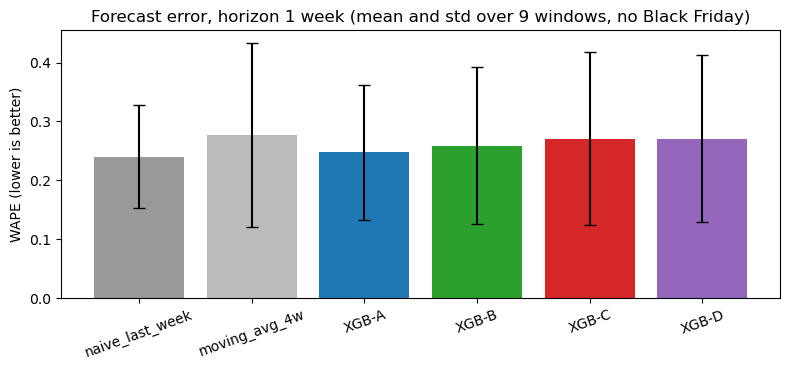

In [20]:
# Bar chart: mean WAPE with spread across folds
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = ["#999999", "#bbbbbb", "#1f77b4", "#2ca02c", "#d62728", "#9467bd"]
ax.bar(main.index, main["WAPE"], yerr=main["WAPE_sd"], color=colors, capsize=4)
ax.set_ylabel("WAPE (lower is better)")
ax.set_title(f"Forecast error, horizon {H} week (mean and std over {len(folds)} windows, no Black Friday)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(FIGURES / f"04_wape_by_model_h{H}.png", dpi=150)
plt.show()

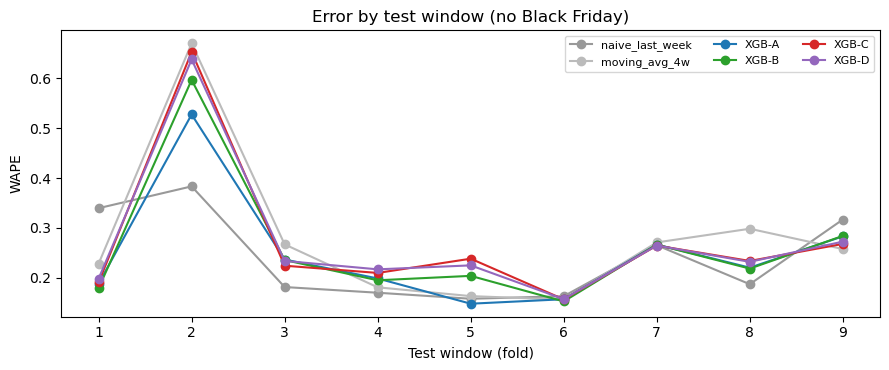

model,naive_last_week,moving_avg_4w,XGB-A,XGB-B,XGB-C,XGB-D
fold,,,,,,
1,0.340,0.228,0.188,0.179,0.191,0.198
2,0.383,0.670,0.528,0.597,0.653,0.638
3,0.181,0.267,0.237,0.235,0.224,0.234
4,0.170,0.181,0.199,0.195,0.210,0.217
5,0.158,0.163,0.148,0.204,0.238,0.225
6,0.163,0.156,0.157,0.152,0.157,0.157
7,0.265,0.271,0.267,0.266,0.265,0.265
8,0.187,0.298,0.220,0.218,0.234,0.232
9,0.317,0.258,0.283,0.284,0.268,0.272


In [21]:
# The same, window by window: do the models rank the same way in every window?
pv = fs_noBF[fs_noBF["horizon"] == H].groupby(["fold", "model"])["WAPE"].mean().unstack()[order]
fig, ax = plt.subplots(figsize=(9, 3.8))
for m, c in zip(order, colors):
    ax.plot(pv.index, pv[m], marker="o", color=c, label=m, lw=1.5)
ax.set_xlabel("Test window (fold)"); ax.set_ylabel("WAPE")
ax.set_title("Error by test window (no Black Friday)"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / f"04_wape_by_fold_h{H}.png", dpi=150)
plt.show()
pv.round(3)

## 5. Does sentiment help? (the central question)

For each comparison we look at the **difference in WAPE** (second model minus first): **negative = the second model is better**. Two complementary views:

- **Windows won**: in how many of the 9 test windows is the second model better?
- **Bootstrap interval**: we resample test weeks 2,000 times to see how much the difference could move by pure chance. If the **95% interval contains 0**, we cannot claim a real difference.

How to read the result:
- Interval entirely below 0 -> the extra information helps.
- Interval around 0 -> no detectable effect (a valid and honest finding).
- Interval entirely above 0 -> the extra information hurts (typically overfitting: more features than the data can support).

In [22]:
pairs = [("XGB-A", "XGB-B"), ("XGB-A", "XGB-C"), ("XGB-A", "XGB-D"), ("XGB-C", "XGB-D"), ("XGB-C", "XGB-B"),
         ("moving_avg_4w", "XGB-A")]
rows = []
fold_wape = fs_noBF[fs_noBF["horizon"] == H].groupby(["fold", "model"])["WAPE"].mean().unstack()
for a, b in pairs:
    r = fu.paired_bootstrap(allp, a, b, H, n_boot=2000, seed=0, exclude_target_weeks=BF)
    r["windows_b_better"] = f"{int((fold_wape[b] < fold_wape[a]).sum())} / {len(fold_wape)}"
    rows.append(r)
comp = pd.DataFrame(rows)[["model_a", "model_b", "diff_wape", "ci_low", "ci_high", "windows_b_better", "share_b_better"]]
comp["verdict"] = np.where(comp["ci_high"] < 0, "b better", np.where(comp["ci_low"] > 0, "b worse", "no clear difference"))
comp.to_csv(TABLES / f"04_model_comparison_h{H}.csv", index=False)
comp.round(4)

,model_a,model_b,diff_wape,ci_low,ci_high,windows_b_better,share_b_better,verdict
0,XGB-A,XGB-B,0.0093,-0.0048,0.0279,6 / 9,0.1145,no clear difference
1,XGB-A,XGB-C,0.0129,-0.0056,0.0369,4 / 9,0.1115,no clear difference
2,XGB-A,XGB-D,0.0148,-0.0031,0.0374,3 / 9,0.0585,no clear difference
3,XGB-C,XGB-D,0.0019,-0.0040,0.0075,3 / 9,0.2575,no clear difference
4,XGB-C,XGB-B,-0.0037,-0.0140,0.0062,6 / 9,0.7615,no clear difference
5,moving_avg_4w,XGB-A,-0.0239,-0.0507,0.0010,6 / 9,0.9670,no clear difference


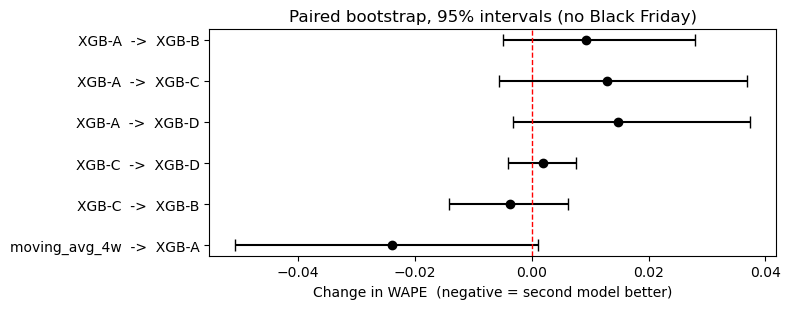

In [23]:
# Forest-style plot of the differences with their 95% intervals
fig, ax = plt.subplots(figsize=(8, 3.2))
labels = [f"{a}  ->  {b}" for a, b in zip(comp["model_a"], comp["model_b"])]
y = np.arange(len(comp))[::-1]
ax.errorbar(comp["diff_wape"], y, xerr=[comp["diff_wape"] - comp["ci_low"], comp["ci_high"] - comp["diff_wape"]],
            fmt="o", color="black", capsize=4)
ax.axvline(0, color="red", ls="--", lw=1)
ax.set_yticks(y); ax.set_yticklabels(labels)
ax.set_xlabel("Change in WAPE  (negative = second model better)")
ax.set_title("Paired bootstrap, 95% intervals (no Black Friday)")
plt.tight_layout()
plt.savefig(FIGURES / f"04_bootstrap_differences_h{H}.png", dpi=150)
plt.show()

## 6. Category by category

The pooled model is scored on each category separately. Careful: with 12 categories and only 36 test weeks, a few categories will look better or worse **by chance**. Do not build the story on a single category; look for a pattern.

model,naive_last_week,moving_avg_4w,XGB-A,XGB-B,XGB-C,XGB-D,avg_weekly_orders
category,,,,,,,
bed_bath_table,0.214,0.223,0.230,0.231,0.215,0.228,113.0
health_beauty,0.186,0.255,0.211,0.240,0.212,0.222,103.0
sports_leisure,0.189,0.226,0.179,0.203,0.220,0.231,91.0
computers_accessories,0.262,0.315,0.305,0.304,0.317,0.306,80.0
furniture_decor,0.260,0.322,0.278,0.287,0.292,0.293,75.0
housewares,0.220,0.238,0.204,0.206,0.216,0.207,69.0
watches_gifts,0.226,0.283,0.226,0.231,0.245,0.237,67.0
telephony,0.236,0.256,0.225,0.227,0.241,0.238,50.0
toys,0.244,0.371,0.323,0.375,0.396,0.395,46.0


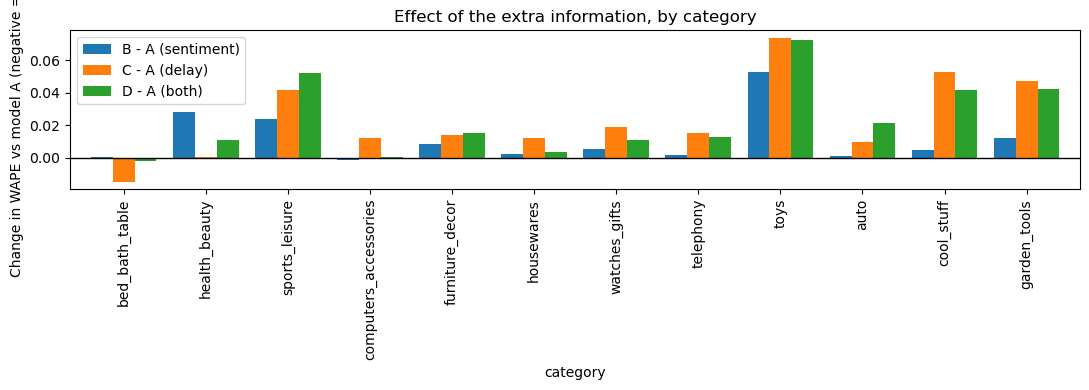

Categories where each extra helps (negative):
B - A (sentiment)    1
C - A (delay)        1
D - A (both)         1


In [24]:
cat_tab = (fs_noBF[fs_noBF["horizon"] == H].groupby(["category", "model"])["WAPE"].mean().unstack()[order])
cat_tab["avg_weekly_orders"] = model_table.groupby("category")["orders_l0"].mean().round(0)
cat_tab = cat_tab.sort_values("avg_weekly_orders", ascending=False)
cat_tab.to_csv(TABLES / f"04_wape_by_category_h{H}.csv")
display(cat_tab.round(3))

delta = pd.DataFrame({"B - A (sentiment)": cat_tab["XGB-B"] - cat_tab["XGB-A"],
                      "C - A (delay)": cat_tab["XGB-C"] - cat_tab["XGB-A"],
                      "D - A (both)": cat_tab["XGB-D"] - cat_tab["XGB-A"]})
ax = delta.plot(kind="bar", figsize=(11, 4), width=0.8)
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("Change in WAPE vs model A (negative = better)")
ax.set_title("Effect of the extra information, by category")
plt.tight_layout()
plt.savefig(FIGURES / f"04_delta_by_category_h{H}.png", dpi=150)
plt.show()
print("Categories where each extra helps (negative):")
print((delta < 0).sum().to_string())

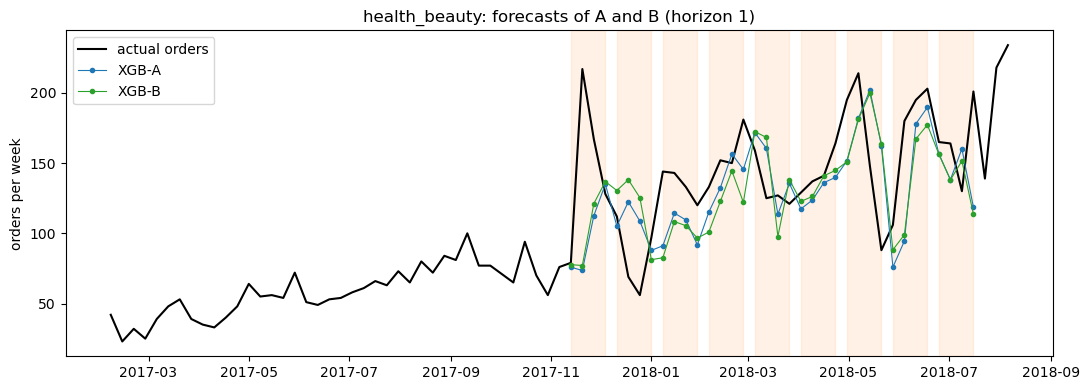

In [25]:
# Example category: actual orders and forecasts of A and B on the test windows
cat = cv.get("example_category", model_table["category"].iloc[0])
series = model_table[model_table["category"] == cat].set_index("week")["orders_l0"]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(series.index, series.values, color="black", lw=1.5, label="actual orders")
for _, f in folds.iterrows():
    ax.axvspan(f["test_start"], f["test_end"], color="tab:orange", alpha=0.10)
for name, c in [("XGB-A", "tab:blue"), ("XGB-B", "tab:green")]:
    q = preds_xgb[(preds_xgb["category"] == cat) & (preds_xgb["model"] == name)].sort_values("target_week")
    ax.plot(q["target_week"], q["y_pred"], "o-", ms=3, lw=0.8, color=c, label=name)
ax.set_title(f"{cat}: forecasts of A and B (horizon {H})"); ax.set_ylabel("orders per week"); ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / f"04_forecast_example_h{H}.png", dpi=150)
plt.show()

## 7. Summary and notes for the report

**What notebook 04 delivered**
- Four XGBoost models (A, B, C, D) tuned and tested with 9 rolling windows, compared with two baselines.
- The mean and spread of WAPE / MAE / RMSE, with and without the Black Friday week.
- A paired bootstrap telling whether the effect of sentiment (B vs A) and delay (C vs A) is distinguishable from chance.
- A category-level view of the effect.

**Points to discuss in the report (write them in your own words)**
- Does XGB-A beat the baselines? If not, sales history alone gives little and any gain from sentiment is hard to find.
- B vs A is the answer to the research question; C vs A and B vs C show whether sentiment adds anything beyond the delay.
- Honest limits: only 79 weeks, one Black Friday, 9 windows (spread is large), sentiment is known about 2 weeks after the purchase, so it is more a *lagging* signal than a leading one. A null result is a legitimate finding.
- Why the target is a ratio and the model pooled.

**Next (notebook 05):** horizons 2 and 4 weeks, feature importance, permutation importance and SHAP (what the models actually use), and robustness checks.

*Suggested commit message:* `Add notebook 04: XGBoost models A-D with rolling-window tuning and paired comparison`